# K-Means Clustering in Python

K-Means is an unsupervised machine learning algorithm used to group similar data points into clusters. we will explain the concepts, different clustering methods, five practical Python examples, and a complete ML workflow with data visualization, preprocessing, training, testing, and evaluation.

We'll use Python, pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

1. What is K-Means clustering?

Suppose a shopping company has information about its customers, including their annual income and spending score. The company wants to group customers into categories such as:

- High income, high spending
- High income, low spending
- Low income, high spending
- Low income, low spending

There is no predefined target column telling us which group each customer belongs to. K-Means discovers groups based on similarities in the data.

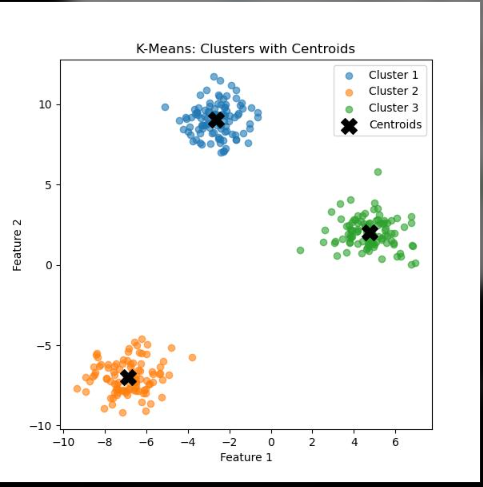

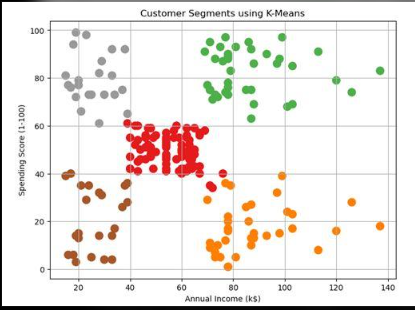

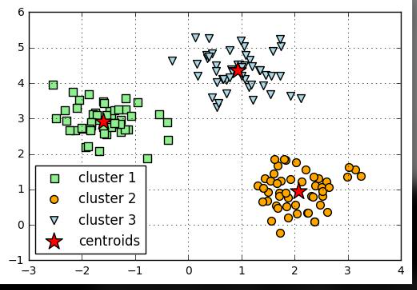

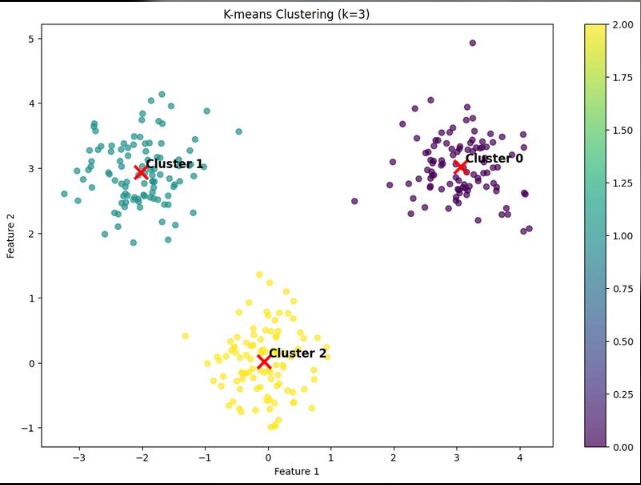

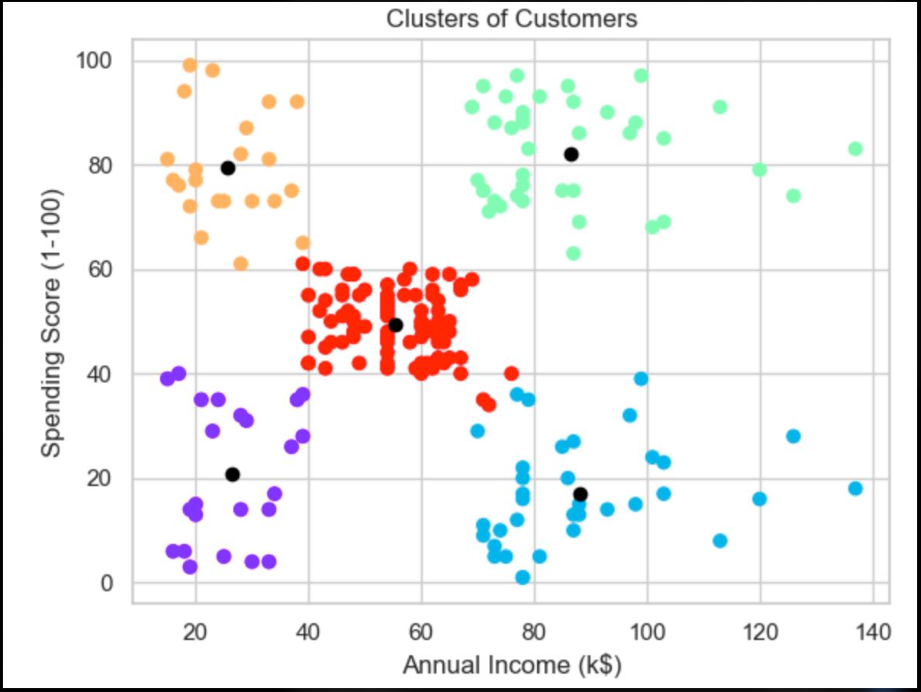

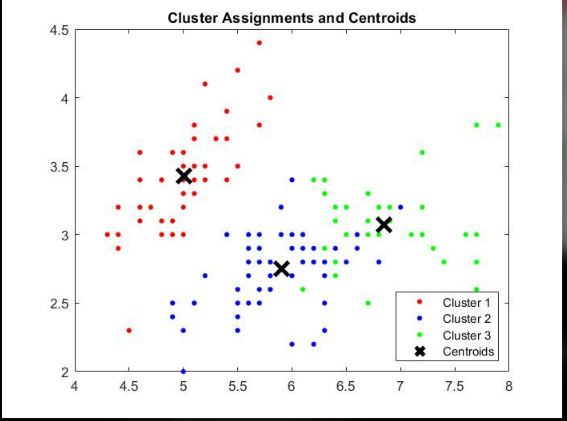

Important K-Means terminology
|Term	|Meaning
:-------|--------
|K	|Number of clusters
|Centroid	|Mean position of a cluster
|n_clusters	|Number of groups requested
|init="k-means++"	|Method for choosing initial centroids
|n_init	|Number of independent initializations
|max_iter	|Maximum iterations per run
|inertia_	|Sum of squared distances to assigned centroids
|labels_	|Cluster assignment for each training point

K-Means minimizes the within-cluster sum of squared distances

2. Types and variations of K-Means


K-Means itself is one algorithm, but it has several initialization strategies, computational variants, and related clustering methods.


|Method	|What it does	|When to use it
:-------|---------------|-----------------
|Standard K-Means|	Assigns points to the nearest centroid and updates means	|General-purpose numerical data
K-Means++|	Chooses well-spaced initial centroids	|Recommended default initialization
Random initialization|	Starts with randomly chosen centroids	|Simple experiments and comparisons
Mini-Batch K-Means|	Updates clusters using small random batches	|Large datasets
Multiple restarts|	Runs K-Means several times with different initializations	|More reliable clustering results
Bisecting K-Means|	Repeatedly splits clusters into smaller clusters	|Hierarchical-style grouping

Related algorithms, but not types of K-Means:

- K-Medoids: uses representative data points instead of mean-based centroids.
- Hierarchical clustering: creates a hierarchy of nested clusters.
- DBSCAN: finds density-based clusters and can identify noise.
- Gaussian Mixture Models (GMM): models clusters as probability distributions.

A key limitation: K-Means works best when clusters are reasonably compact and roughly spherical. It can perform poorly with irregularly shaped clusters, substantial outliers, or features that have very different scales.

3. Complete ML workflow for K-Means

Unlike supervised learning, K-Means does not learn from a target column such as Survived or Price. It discovers groups from input features.

roblem understanding

Decide what you want to group

2. Load dataset

CSV, database, or generated data

3. Understand and clean data

Check types, missing values, duplicates, outliers

4. EDA and visualization

Histograms, scatter plots, correlations

5. Feature selection and scaling

Select useful numeric columns; standardize them

6. Train/test split (optional)

Useful for checking assignment of unseen observations

7. Select K

Elbow method and silhouette score

8. Train K-Means

Fit the model and assign cluster labels

9. Evaluate and visualize clusters

Silhouette score, cluster sizes, scatter plots

10. Save and deploy

Save the scaler and model; cluster new

Why do we perform each step?

|Step	|Why we do it
:-------|---------------
|Data cleaning	|Missing or invalid values can prevent clustering or distort results.
|EDA	|Helps us understand distributions and possible groupings.
|Feature selection	|Irrelevant features can distort distances.
|Scaling	|A feature with large numeric values can dominate Euclidean distance.
|Elbow method	|Helps identify a useful candidate for K.
|Silhouette score	|Measures how well-separated the clusters are.
|Training	|Learns the cluster centroids.
|Testing	|Checks how new observations are assigned to learned centroids.
|Saving	|Allows consistent clustering of new data later.

Important: K-Means does not require a train/test split in the same way that a classification or regression model does. For a clustering project, you can fit it on all suitable data. If you want to test generalization, fit the scaler and K-Means on training data, then transform and assign the test data using those same fitted objects.

4. Python setup

Install the required libraries in your VS Code terminal or notebook.

python -m pip install numpy pandas matplotlib seaborn scikit-learn joblib

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import make_blobs, load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

What each library does:
- NumPy: numerical calculations.
- pandas: data manipulation and cleaning.
- Matplotlib and Seaborn: data visualization.
- StandardScaler: scales numerical features.
- KMeans: builds the clustering model.
- PCA: projects high-dimensional data into two dimensions for visualization.
- silhouette_score: evaluates cluster separation.
- joblib: saves the trained model and scaler.

Example 1 — Complete K-Means ML project

Problem statement: A company has customer-like observations with two numerical features. Build a clustering model that discovers groups, choose K using the elbow and silhouette methods, visualize the clusters, evaluate assignments on held-out data, and save the model.

This example generates its own dataset, so you don't need to download a CSV file.

Step 1: Generate the dataset

In [2]:
from sklearn.datasets import make_blobs

X, actual_groups = make_blobs(
    n_samples=600,
    centers=4,
    n_features=2,
    cluster_std=1.2,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Annual_Income", "Spending_Score"]
)

print(df.head())
print(df.shape)
print(df.isnull().sum())
print(df.describe())

   Annual_Income  Spending_Score
0      -7.808174       -8.373695
1      -6.536589       -6.478761
2      -4.881058       -5.662866
3      -4.120949       -7.315516
4       4.757090        1.045558
(600, 2)
Annual_Income     0
Spending_Score    0
dtype: int64
       Annual_Income  Spending_Score
count     600.000000      600.000000
mean       -3.340030        2.889826
std         5.257646        6.269308
min       -11.837615       -9.368178
25%        -7.648739       -1.522165
50%        -4.508638        4.439259
75%         0.619771        8.173745
max         8.334536       13.637564


Explanation:
- n_samples=600: generates 600 observations.
- centers=4: generates four underlying groups for this demonstration.
- n_features=2: creates two numeric features.
- random_state=42: makes the generated data reproducible.
- actual_groups contains the synthetic generator's original group IDs. We will not use them to train K-Means.
In a real business dataset, the underlying groups are unknown.

Step 2: Visualize the original data

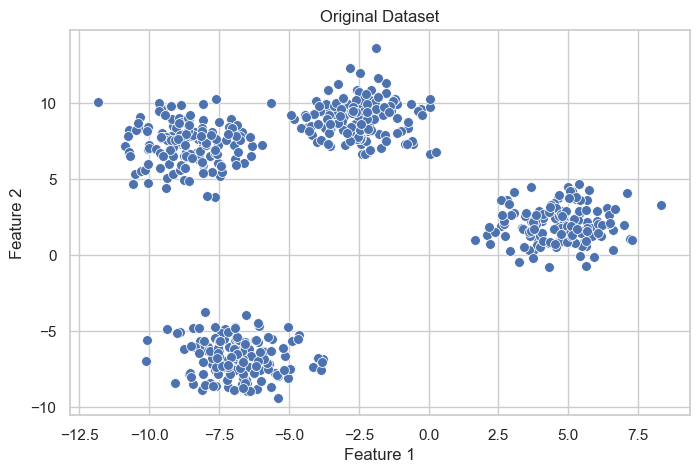

In [3]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    s=50
)

plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Why? A scatter plot helps you identify whether the observations appear to form groups and whether there are unusual points.

Step 3: Clean and split the data

In [4]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Fill missing values if present
df = df.fillna(df.median(numeric_only=True))

X = df[["Annual_Income", "Spending_Score"]]

X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (480, 2)
Testing data: (120, 2)


We use 80% of the observations for training and 20% for testing. Because the generated dataset has no missing values or duplicates, the cleaning operations usually won't change it.

Step 4: Scale the features

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Why scale? K-Means uses distances. Standardization puts features on comparable scales.

- fit_transform() learns the scaling parameters from the training set and applies them.
- transform() applies those same parameters to the test set without learning from it.

Never fit a separate scaler to the test set.

Step 5: Find the best K using the elbow method

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have

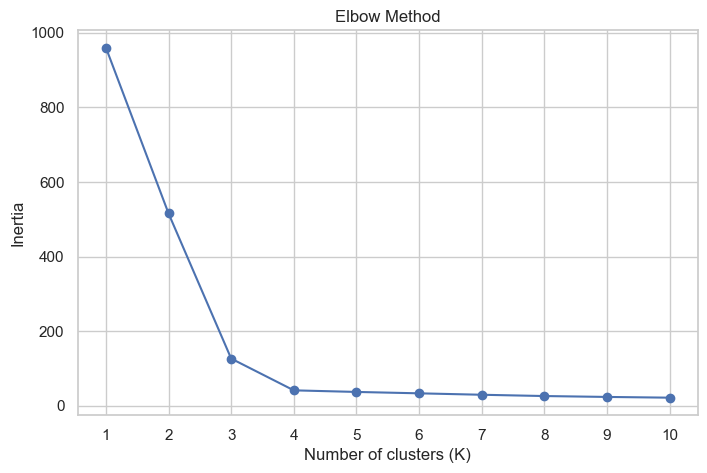

In [6]:
inertias = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    model.fit(X_train_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

How to interpret the graph: Inertia always decreases as K increases. Look for the point where the decrease begins to slow noticeably, forming an elbow. That is a candidate K, not proof that it is the only correct choice.

Step 6: Compare K using silhouette score

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have

    K  Silhouette_Score
2   4          0.750351
1   3          0.718312
3   5          0.643624
0   2          0.542377
4   6          0.520952
5   7          0.420679
8  10          0.352522
7   9          0.346421
6   8          0.342889


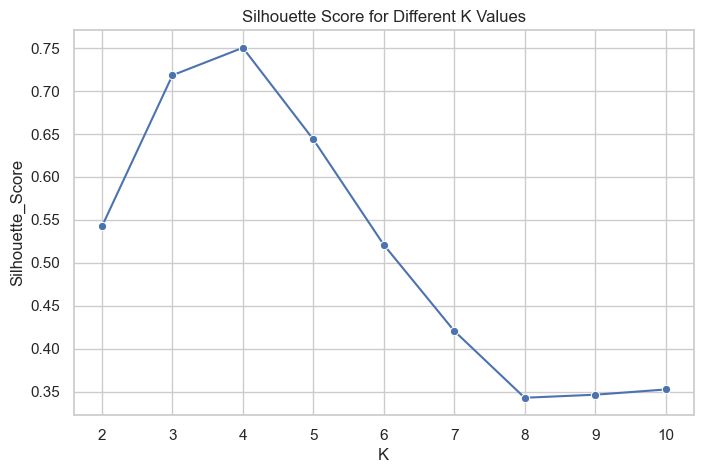

In [7]:
scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_train_scaled)

    score = silhouette_score(X_train_scaled, labels)
    scores.append((k, score))

scores_df = pd.DataFrame(
    scores,
    columns=["K", "Silhouette_Score"]
)

print(scores_df.sort_values(
    "Silhouette_Score",
    ascending=False
))

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=scores_df,
    x="K",
    y="Silhouette_Score",
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.show()

Silhouette scores range from -1 to 1:


- Close to 1: clusters are well-separated.
- Around 0: clusters overlap or points are near boundaries.
- Below 0: some points may be assigned to inappropriate clusters.


Use the elbow, silhouette score, and business requirements together rather than automatically selecting whichever K has the highest score.

Step 7: Train the final model


For this synthetic dataset, we know four groups were generated. In a real project, you would decide K based on the preceding diagnostics and domain knowledge.

In [11]:
best_k = 4

kmeans = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

kmeans.fit(X_train_scaled)

print("Centroids:")
print(kmeans.cluster_centers_)

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Centroids:
[[-0.66130822 -1.56050772]
 [ 0.14847891  0.97271358]
 [ 1.52468352 -0.16760383]
 [-1.00330431  0.69891247]]


fit() learns the centroids. Cluster IDs such as 0, 1, 2, and 3 are arbitrary labels; they do not indicate ranking.

Step 8: Predict clusters and visualize them

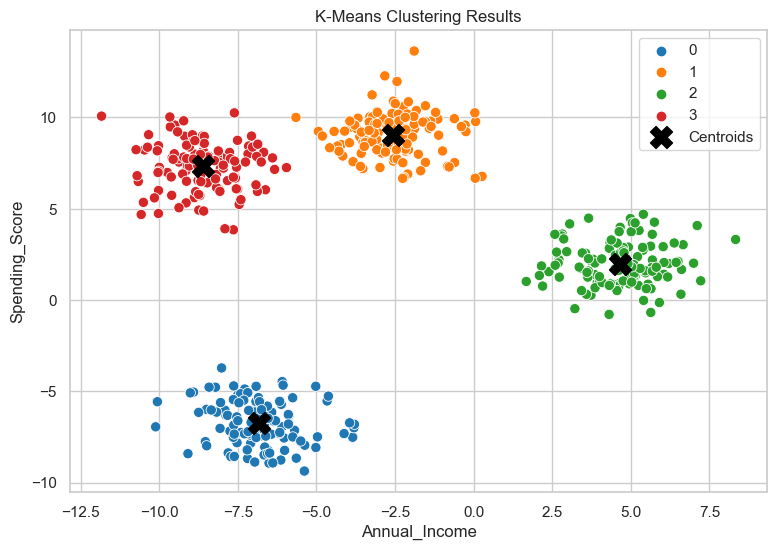

In [12]:
train_labels = kmeans.predict(X_train_scaled)
test_labels = kmeans.predict(X_test_scaled)

train_results = X_train.copy()
train_results["Cluster"] = train_labels

test_results = X_test.copy()
test_results["Cluster"] = test_labels

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=train_results,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="tab10",
    s=55
)

centers_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clustering Results")
plt.legend()
plt.show()

The colored points are the training observations, and the black X markers are the centroids shown in the original feature units.

Step 9: Evaluate the model

In [13]:
train_silhouette = silhouette_score(
    X_train_scaled,
    train_labels
)

test_silhouette = silhouette_score(
    X_test_scaled,
    test_labels
)

print("Training silhouette:", round(train_silhouette, 3))
print("Testing silhouette:", round(test_silhouette, 3))

print("\nTraining cluster sizes:")
print(pd.Series(train_labels).value_counts().sort_index())

print("\nTesting cluster sizes:")
print(pd.Series(test_labels).value_counts().sort_index())

Training silhouette: 0.75
Testing silhouette: 0.76

Training cluster sizes:
0    117
1    120
2    120
3    123
Name: count, dtype: int64

Testing cluster sizes:
0    33
1    29
2    30
3    28
Name: count, dtype: int64


These scores describe the quality of the discovered groupings. There is no accuracy score unless you have meaningful reference labels and an appropriate comparison method. The test silhouette is a useful diagnostic, though a small test set may produce a less stable estimate.

Step 10: Save the model

In [14]:
joblib.dump(scaler, "kmeans_scaler.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")

print("Model and scaler saved.")

Model and scaler saved.


Predict clusters for a new observation:

In [15]:
loaded_scaler = joblib.load("kmeans_scaler.pkl")
loaded_model = joblib.load("kmeans_model.pkl")

new_customer = pd.DataFrame(
    [[55, 70]],
    columns=["Annual_Income", "Spending_Score"]
)

new_customer_scaled = loaded_scaler.transform(new_customer)

cluster = loaded_model.predict(new_customer_scaled)

print("Assigned cluster:", cluster[0])

Assigned cluster: 2


The new values must use the same feature meanings and units as the training data. In this generated example, the feature names are illustrative, not real currency or actual spending-score measurements.

### Example 2 — Customer segmentation using K-Means



Problem statement: An e-commerce company wants to group customers based on annual income and spending score to help design targeted marketing campaigns.

This example uses a small, manually created customer dataset.

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


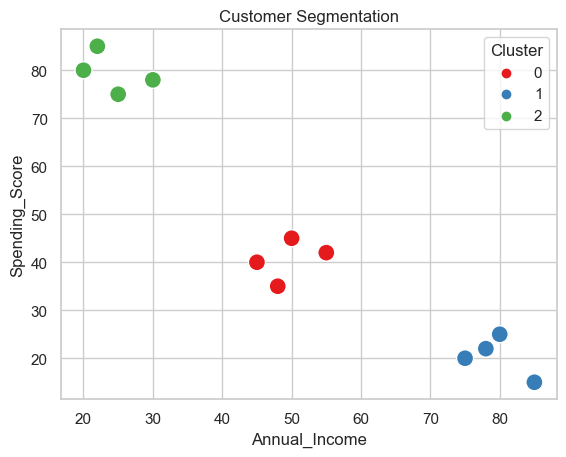

         Annual_Income  Spending_Score
Cluster                               
0                49.50            40.5
1                79.50            20.5
2                24.25            79.5
Silhouette score: 0.796


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

customers = pd.DataFrame({
    "Customer_ID": range(1, 13),
    "Annual_Income": [
        20, 25, 22, 30,
        45, 50, 48, 55,
        75, 80, 85, 78
    ],
    "Spending_Score": [
        80, 75, 85, 78,
        40, 45, 35, 42,
        20, 25, 15, 22
    ]
})

# Select features
X = customers[["Annual_Income", "Spending_Score"]]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train K-Means
model = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

customers["Cluster"] = model.fit_predict(X_scaled)

# Visualize
sns.scatterplot(
    data=customers,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="Set1",
    s=150
)

plt.title("Customer Segmentation")
plt.show()

# Understand each cluster
print(customers.groupby("Cluster")[
    ["Annual_Income", "Spending_Score"]
].mean().round(2))

print(
    "Silhouette score:",
    round(silhouette_score(X_scaled, customers["Cluster"]), 3)
)

**What are we learning?**


- groupby("Cluster").mean() shows the typical income and spending score of each group.
- The scatter plot displays the groups visually.
- The silhouette score helps assess whether the groups are separated.
Business use case: Marketing teams can develop different promotions for different customer segments. However, the cluster labels themselves do not tell us which group is best or most profitable; that requires further business analysis.

### Example 3 — Iris flower clustering using four features
* Problem statement: Group iris flowers using their sepal length, sepal width, petal length, and petal width, without using the species label to train the model.

The Iris dataset is built into Scikit-learn, so no download is needed.

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Shape: (150, 4)


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Cluster counts:
0    53
1    50
2    47
Name: count, dtype: int64
Silhouette score: 0.46


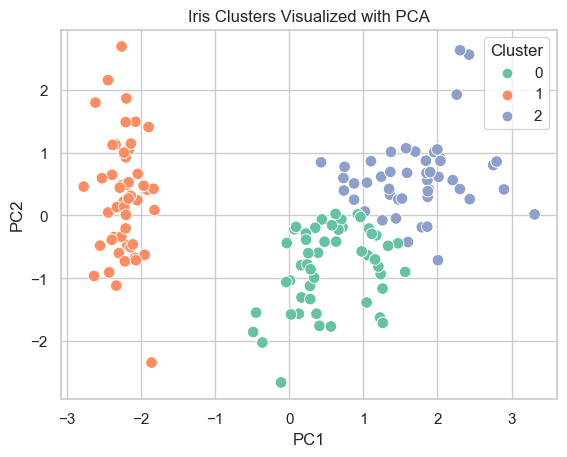

Variance retained by two components: 0.958


In [18]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print(X.head())
print("Shape:", X.shape)

# Scale all four features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means
model = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

labels = model.fit_predict(X_scaled)

print("Cluster counts:")
print(pd.Series(labels).value_counts().sort_index())

print(
    "Silhouette score:",
    round(silhouette_score(X_scaled, labels), 3)
)

# Reduce four features to two dimensions for plotting
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": labels
})

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=70
)

plt.title("Iris Clusters Visualized with PCA")
plt.show()

print(
    "Variance retained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3)
)

Step-by-step explanation

1. load_iris() provides 150 observations with four numerical features.
2. StandardScaler() ensures that each feature contributes on a comparable scale.
3. K-Means discovers three groups without knowing the species.
4. PCA reduces four dimensions to two for visualization.
5. The variance ratio tells you how much information the two-dimensional projection retains.



* Important: PCA is only used here to visualize the clusters. The K-Means model was trained on all four standardized features. Its cluster IDs will not necessarily match the true flower species exactly.

### Example 4 — Wine dataset clustering
* Problem statement: A data analyst wants to group wine samples according to their chemical characteristics, such as alcohol, color intensity, and other laboratory measurements.

This example uses all numerical features in Scikit-learn's Wine dataset.

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Cluster sizes:
0    65
1    51
2    62
Name: count, dtype: int64

Silhouette score: 0.285

Average feature values by cluster:
         alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  \
Cluster                                                            
0          12.25        1.90  2.23              20.06      92.74   
1          13.13        3.31  2.42              21.24      98.67   
2          13.68        2.00  2.47              17.46     107.97   

         total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
Cluster                                                                     
0                 2.25        2.05                  0.36             1.62   
1                 1.68        0.82                  0.45             1.15   
2                 2.85        3.00                  0.29             1.92   

         color_intensity   hue  od280/od315_of_diluted_wines  proline  
Cluster                                                                
0 

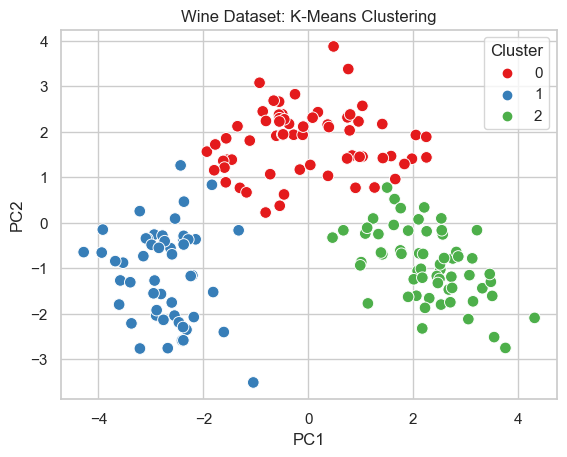

In [20]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

print(X.head())
print("Dataset shape:", X.shape)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train model
model = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

clusters = model.fit_predict(X_scaled)

print("\nCluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

print(
    "\nSilhouette score:",
    round(silhouette_score(X_scaled, clusters), 3)
)

# View cluster profiles
cluster_profiles = X.copy()
cluster_profiles["Cluster"] = clusters

print("\nAverage feature values by cluster:")
print(cluster_profiles.groupby("Cluster").mean().round(2))

# Visualize with PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": clusters
})

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=70
)

plt.title("Wine Dataset: K-Means Clustering")
plt.show()

### Why is this example different?
The Iris example has four features, while the Wine dataset has 13 numerical features. The same K-Means process can work with both, but visualization becomes harder when there are many features.

PCA makes the groups easier to inspect visually. Because the projection can lose information, evaluate the clusters in the original standardized feature space as well.

Real-world use case: Explore whether samples with similar chemical characteristics form groups. Do not assume these groups represent wine quality or a specific wine variety without validating that interpretation.

### Example 5 — Mini-Batch K-Means for larger datasets
* Problem statement: An online platform has hundreds of thousands of customer records. Standard K-Means can be computationally expensive on very large datasets, so the analyst wants to try Mini-Batch K-Means.

Mini-Batch K-Means updates centroids using small random batches rather than processing the entire dataset for every update.

c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1962: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 1024 or by setting the environment variable OMP_NUM_THREADS=2
  warnings.warn(


Cluster sizes:
Cluster
0    3847
1    4000
2    3985
3    4190
4    3978
Name: count, dtype: int64
Silhouette score on a sample: 0.546


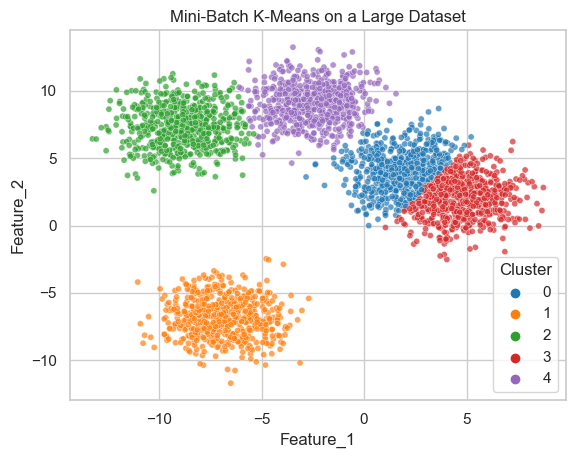

In [21]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate 20,000 observations
X, _ = make_blobs(
    n_samples=20000,
    centers=5,
    n_features=2,
    cluster_std=1.5,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Fit Mini-Batch K-Means
model = MiniBatchKMeans(
    n_clusters=5,
    batch_size=512,
    n_init=3,
    random_state=42
)

labels = model.fit_predict(X_scaled)

df["Cluster"] = labels

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

print(
    "Silhouette score on a sample:",
    round(
        silhouette_score(
            X_scaled,
            labels,
            sample_size=2000,
            random_state=42
        ),
        3
    )
)

# Plot a sample to keep the chart readable
plot_df = df.sample(n=3000, random_state=42)

sns.scatterplot(
    data=plot_df,
    x="Feature_1",
    y="Feature_2",
    hue="Cluster",
    palette="tab10",
    s=20,
    alpha=0.7
)

plt.title("Mini-Batch K-Means on a Large Dataset")
plt.show()

### Explanation
- batch_size=512 controls the number of samples in each update batch.
- n_init=3 runs three initializations and keeps the best result among them.
- sample_size=2000 estimates the silhouette score using a sample, making evaluation less expensive.
- Plotting only 3,000 observations keeps the visualization readable.

Mini-Batch K-Means can be faster on large datasets, but its results may differ slightly from standard K-Means. Compare clustering quality as well as execution time when deciding which to use.

### 5. Compare the five examples
- Example	Dataset	Main concept learned
1.	Generated 2D data	Complete ML workflow, train/test split, elbow, silhouette, saving model
2.	Customer data	Customer segmentation and cluster profiling
3.	Iris	Clustering four features and visualizing with PCA
4.	Wine	High-dimensional clustering and feature analysis
5.	20,000 generated samples	Mini-Batch K-Means for larger datasets

6. Common mistakes to avoid
* Mistake 1: Not scaling features

A feature measured in thousands may dominate a feature measured between 0 and 1. Use StandardScaler or another suitable scaling method.


* Mistake 2: Choosing K without checking

Compare the elbow plot, silhouette score, cluster sizes, and practical meaning.


* Mistake 3: Treating cluster IDs as meaningful categories

Cluster 2 is not automatically better than cluster 1. IDs are arbitrary.


* Mistake 4: Using accuracy as the main metric

K-Means has no target labels by default. Use silhouette score, inertia, cluster profiles, and domain validation instead.


* Mistake 5: Fitting preprocessing on test data

Fit the scaler on training data only, then use that same scaler to transform test data and future observations.

* Your practice checklist
0 of 5

* [ ] 1. Retail customer segmentation

Cluster customers using annual income, spending score, and purchase frequency. Compare K values from 2 to 8.


* [ ] 2. Student performance grouping

Group students using study hours, attendance, and assignment completion. Explain each cluster's profile.


* [ ] 3. Employee analytics

Cluster employees using satisfaction, evaluation score, and monthly working hours. Investigate whether distinct groups emerge.


* [ ] 4. E-commerce product grouping

Cluster products using price, rating, sales volume, and return rate after appropriate scaling.


* [ ] 5. Compare clustering algorithms

Run K-Means and DBSCAN on a dataset with irregularly shaped groups. Compare the plots and silhouette scores where applicable.

* Final revision
Remember this sequence for a K-Means project:

* Understand data → Clean data → EDA → Select features → Scale → Choose K → Fit K-Means → Assign clusters → Visualize → Evaluate → Save model 

- → Cluster new data.


* The most important practical skills are scaling correctly, selecting a sensible K, interpreting cluster profiles, and applying the saved scaler and model consistently to new observations.